# **CENG 463 – Introduction to Machine Learning HW2**

## **TASK 1: BAG OF WORDS**

/tmp/ipykernel_13549/829997273.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(vocab, rotation=45)
/tmp/ipykernel_13549/829997273.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(vocab, rotation=45)
/tmp/ipykernel_13549/829997273.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(vocab, rotation=45)


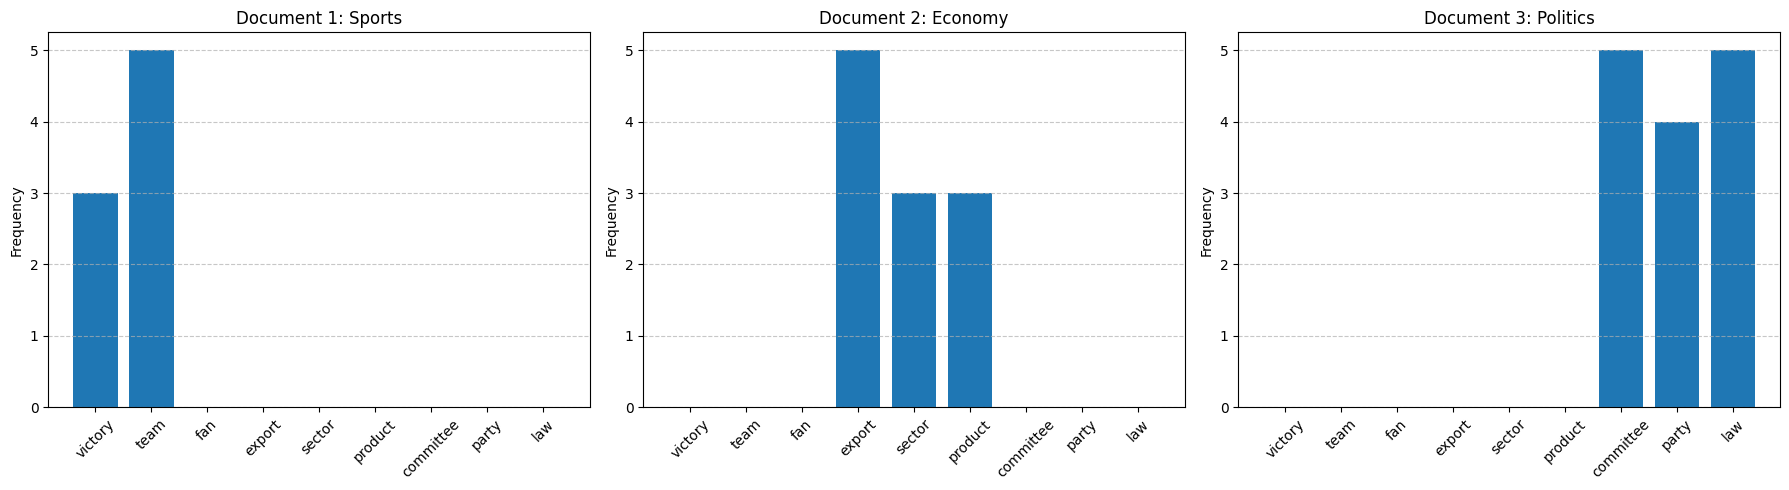

In [ ]:
import numpy as np
import re
import matplotlib.pyplot as plt    

# Define vocabulary and files
vocab = ["victory", "team", "fan", "export", "sector", "product", "committee", "party", "law"]
files = ["sports.txt", "economy.txt", "politics.txt"]

#helper function to read files
def read_file(file_path):
    with open(file_path, 'r', encoding="utf-8") as file:
        return file.read().lower() #convert to lowercase for uniformity
    
#create frequency matrix
freq_matrix = np.zeros((len(files), len(vocab)), dtype=int) #rows: files, columns: vocab

#add frequencies to matrix
for i, file in enumerate(files):
    content = read_file(file)
    #TOKENIZE content in each document into words

    #re is the regex module in python
    #findall returns a list of all words matching the regex pattern
    #r indicates a raw string where backslashes are treated literally
    #\b matches word boundaries, \w+ matches one or more word characters (letters, digits, underscores)
    #\b\w+\b matches whole words
    words = re.findall(r'\b\w+\b', content)

    #count frequencies of each vocab word in the document for each document
    for j, word in enumerate(vocab):
        freq_matrix[i, j] = words.count(word)


#visualize frequency matrix
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
titles = ["Document 1: Sports", "Document 2: Economy", "Document 3: Politics"]

#create bar charts for each document
for i in range(freq_matrix.shape[0]):
    axes[i].bar(vocab, freq_matrix[i], color='#1f77b4')
    axes[i].set_title(titles[i])
    axes[i].set_xticklabels(vocab, rotation=45)
    axes[i].set_ylabel("Frequency")
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

#printing vectors for project report(uncomment later)
# for i, f in enumerate(files):
#     print(f"{f} Vector: {freq_matrix[i]}")

## **TASK 2: TEXT CLASSIFICATION**

In [ ]:
# TO DO

       Word  Chi2 Statistic
5      free             9.0
8     smile             4.5
3  discount             3.0


### **Step 1: Chi-Square Feature Selection**

In [2]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2  

#define the dataset in the PDF
train_data = [
    "free free free buy discount combo pleasure",  # d1
    "free free free discount pleasure smile smile smile", # d2
    "cat mouse", # d3
    "cat cat dog dog dog dog", # d4
    "mouse" # d5
]
train_labels = [1, 1, 0, 0, 0]  # 1: spam, 0: not spam

#vectorize the dataset into count vectors for Chi-Square 
vectorizer = CountVectorizer()
X_train = vectorizer.fit_transform(train_data)#fit_transform creates the vocabulary and transforms the data into count vectors
feature_names = vectorizer.get_feature_names_out()#get the feature names (words) from the vectorizer

#compute Chi-Square statistics
chi2_stats, p_values = chi2(X_train, train_labels)

#display results in a DataFrame for better readability
chi2_df = pd.DataFrame({"Word": feature_names, "Chi2 Statistic": chi2_stats,})
chi2_df = chi2_df.sort_values(by="Chi2 Statistic", ascending=False) #sort by Chi2 statistic

#store and show top discriminative 3 words
top_3_discr= chi2_df.head(3)
print("Top 3 Discriminative Words based on Chi-Square Statistic:")
print(top_3_discr)

#NOTE for Report: 
#must manually show the calculation for 'free' in your PDF report as requested.

Top 3 Discriminative Words based on Chi-Square Statistic:
       Word  Chi2 Statistic
5      free             9.0
8     smile             4.5
3  discount             3.0


### **Step 2: TF-IDF Representation**

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

#define test data to include in full TF-IDF matrix
test_data = [
    "dog cat mouse cat", # d6
    "free free smile"    # d7
]

#combine train and test data for full TF-IDF matrix
all_data = train_data + test_data

#vectorize the combined dataset into TF-IDF vectors
vocab_list = top_3_discr["Word"].tolist() #get the top 3 discriminative words only their word names not the stats
tfidf_vectorizer = TfidfVectorizer(vocabulary=vocab_list) #use only top 3 discriminative words
X_tfidf = tfidf_vectorizer.fit_transform(all_data)

#create the table requested in the PDF
tfidf_df = pd.DataFrame(X_tfidf.toarray(), columns=vocab_list, index=[f"d{i+1}" for i in range(7)])
#display the TF-IDF table
print("TF-IDF for selected words:")
print(tfidf_df)

TF-IDF for selected words:
        free     smile  discount
d1  0.931664  0.000000  0.363321
d2  0.629845  0.736862  0.245621
d3  0.000000  0.000000  0.000000
d4  0.000000  0.000000  0.000000
d5  0.000000  0.000000  0.000000
d6  0.000000  0.000000  0.000000
d7  0.863169  0.504915  0.000000


### **Step 3: KNN Classification**

In [4]:
from sklearn.neighbors import KNeighborsClassifier

#prepare training and test sets
X_train_knn = X_tfidf[:5]  # first 5 documents for
y_train_knn = train_labels  # corresponding labels
X_test_knn = X_tfidf[5:]   # last 2 documents for testing

#initialize and train KNN classifier
knn_classifier = KNeighborsClassifier(n_neighbors=3)
knn_classifier.fit(X_train_knn, y_train_knn)

#predict labels for test documents
predicted_labels = knn_classifier.predict(X_test_knn)

#print predicted labels
print(f"Prediction for d6 ({test_data[0]}): {'spam' if predicted_labels[0] == 1 else 'not spam'}")
print(f"Prediction for d6 ({test_data[1]}): {'spam' if predicted_labels[1] == 1 else 'not spam'}")

# #for the report: Measure distances manually or output them here uncomment later
# distances, indices = KNeighborsClassifier.kneighbors(X_test_knn)
# print("\nDistances to nearest neighbors:", distances)
# print("Indices of nearest neighbors:", indices)

Prediction for d6 (dog cat mouse cat): not spam
Prediction for d6 (free free smile): spam


## **TASK 3: TOPIC MODELING WITH BERTOPIC**

### **Step 1: Dataset Creation**

In [5]:
from sklearn.datasets import fetch_20newsgroups

#fetch 20 newsgroups dataset
newsgroups_train = fetch_20newsgroups(remove=('headers', 'footers', 'quotes'))#remove headers, footers, quotes to focus on content only

#print all 20 category names
print("all 20 newsgroup categories:")
print(list(newsgroups_train.target_names))

print("\nwe will select 1: alt.atheism, 2: rec.autos, 3: talk.politics.mideast for our 3 categories.") 

#fetch only the selected 3 categories
selected_categories = ['alt.atheism', 'rec.autos', 'talk.politics.mideast']
newsgroups_train_selected = fetch_20newsgroups(subset='train', categories=selected_categories, remove=('headers', 'footers', 'quotes'))#remove headers, footers, quotes to focus on content only

all 20 newsgroup categories:
['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

we will select 1: alt.atheism, 2: rec.autos, 3: talk.politics.mideast for our 3 categories.


### **Step 2: Model Training**

In [ ]:
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP
from hdbscan import HDBSCAN

#1. Create a vectorizer that automatically removes English stopwords
vectorizer_model = CountVectorizer(stop_words="english")

#UMAP with fixed random_state
umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, random_state=42)

#HDBSCAN (stable parameters) with prediction_data enabled for probabilities
hdbscan_model = HDBSCAN(
    min_cluster_size=10,
    metric='euclidean',
    cluster_selection_method='eom',
    prediction_data=True  # REQUIRED for probabilities
)

#initialize BERTopic model
topic_model = BERTopic(
    vectorizer_model=vectorizer_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    calculate_probabilities=True,
    verbose=False
)

#train the model on the newsgroup data
topics, probs = topic_model.fit_transform(newsgroups_train_selected.data)  # topics: assigned topic for each document, probs: probabilities for each topic assignment

#report the number of topics 
topic_info = topic_model.get_topic_info()
print(f"Number of topics identified: {len(topic_info)-1}")  # subtract 1 for the 'outlier' topic
print(topic_info)

### **Step 3: Topic Analysis**

In [ ]:
### **Step 3: Topic Analysis** (Corrected)

import pandas as pd
from collections import Counter

# --- 1. Retrieve Topics from the Trained Model ---
# FIX: Ensure 'topics' is defined by getting it directly from the model attribute
topics = topic_model.topics_

# --- 2. Map Topics to Your Manual Names ---
target_categories = {
    'alt.atheism': 'Atheism',
    'rec.autos': 'Autos',
    'talk.politics.mideast': 'MiddleEast'
}

# Get ground truth data
y_true = newsgroups_train_selected.target
target_names = newsgroups_train_selected.target_names

# Get all topic info from the model
topic_info = topic_model.get_topic_info() 

# Helper: Map a Topic ID to its "Meaningful Name" based on majority ground truth in that cluster
def get_topic_name_from_documents(t_id, topics_array, true_labels, names):
    if t_id == -1: return "Outlier"
    
    # Get indices of all documents assigned to this specific topic
    # This is where the error occurred previously because topics_array was None
    indices = [i for i, x in enumerate(topics_array) if x == t_id]
    
    if not indices: return "Unknown"
    
    # Find the true labels for these specific documents
    labels = [true_labels[i] for i in indices]
    
    # Find the most common ground truth label in this cluster
    most_common_index = Counter(labels).most_common(1)[0][0]
    original_name = names[most_common_index]
    
    # Map to your custom "Meaningful Name"
    return target_categories.get(original_name, original_name)

# Create a dictionary mapping: Topic_ID -> Meaningful Name
topic_mapping = {}
for t_id in topic_info['Topic']:
    topic_mapping[t_id] = get_topic_name_from_documents(t_id, topics, y_true, target_names)

# Update the model's internal labels
topic_model.set_topic_labels(topic_mapping)

# --- 3. Display Top 5 Words per Topic ---
print("\n--- Top 5 Words per Topic (Derived from Document Combination) ---")

# Iterate through every topic found
for t_id in topic_info['Topic']:
    if t_id == -1: continue # Skip outlier topic
    
    # Get the assigned meaningful name
    custom_name = topic_mapping[t_id]
    
    # Get top 5 words for this specific topic cluster
    top_words = [word for word, weight in topic_model.get_topic(t_id)[:5]]
    
    print(f"Topic {t_id} ({custom_name}): {', '.join(top_words)}")

# --- 4. Create Classification Table ---
df_results = pd.DataFrame({
    'Document': newsgroups_train_selected.data,
    'Topic_ID': topics
})

# Map IDs to the Meaningful Names
df_results['Topic_Name'] = df_results['Topic_ID'].map(topic_mapping)

# Filter out outliers for cleaner display
df_clean = df_results[df_results['Topic_ID'] != -1].copy()

# Add a preview of the text for the table
df_clean['Preview'] = df_clean['Document'].str.replace(r'\s+', ' ', regex=True).str.slice(0, 100) + "..."

# Formatting for display
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', None)

print("\n\n--- Document Classification Table (Sample) ---")
print(df_clean.groupby('Topic_Name').head(2)[['Topic_Name', 'Topic_ID', 'Preview']])



--- Top 5 Words per Topic ---
Topic 0 (Autos): the, to, car, and, is
Topic 1 (MiddleEast): the, of, to, in, is
Topic 2 (Atheism): is, that, you, to, be
Topic 3 (MiddleEast): the, of, and, in, armenian
Topic 4 (Autos): ites, testing, ditto, hello, luck
Topic 5 (Atheism): islam, the, to, of, is
Topic 6 (Atheism): is, god, that, of, not
Topic 7 (MiddleEast): to, you, this, posts, of
Topic 8 (Atheism): is, that, atheists, of, god
Topic 9 (MiddleEast): and, they, the, was, to
Topic 10 (MiddleEast): greek, the, of, in, greece
Topic 11 (Atheism): is, system, that, the, be
Topic 12 (Atheism): satan, do, god, the, is
Topic 13 (MiddleEast): of, the, anania, and, problems
Topic 14 (MiddleEast): the, to, us, of, are
Topic 15 (Atheism): enviroleague, to, for, programs, youth
Topic 16 (Atheism): text, the, john, of, are


--- Document Classification Table (Sample) ---
    Topic_Name  Topic_ID                                                                                                  Preview
0 

### **Step 4: Visualization**


--- Step 4: Visualization ---
1. Generating Bar Chart of Top Words...


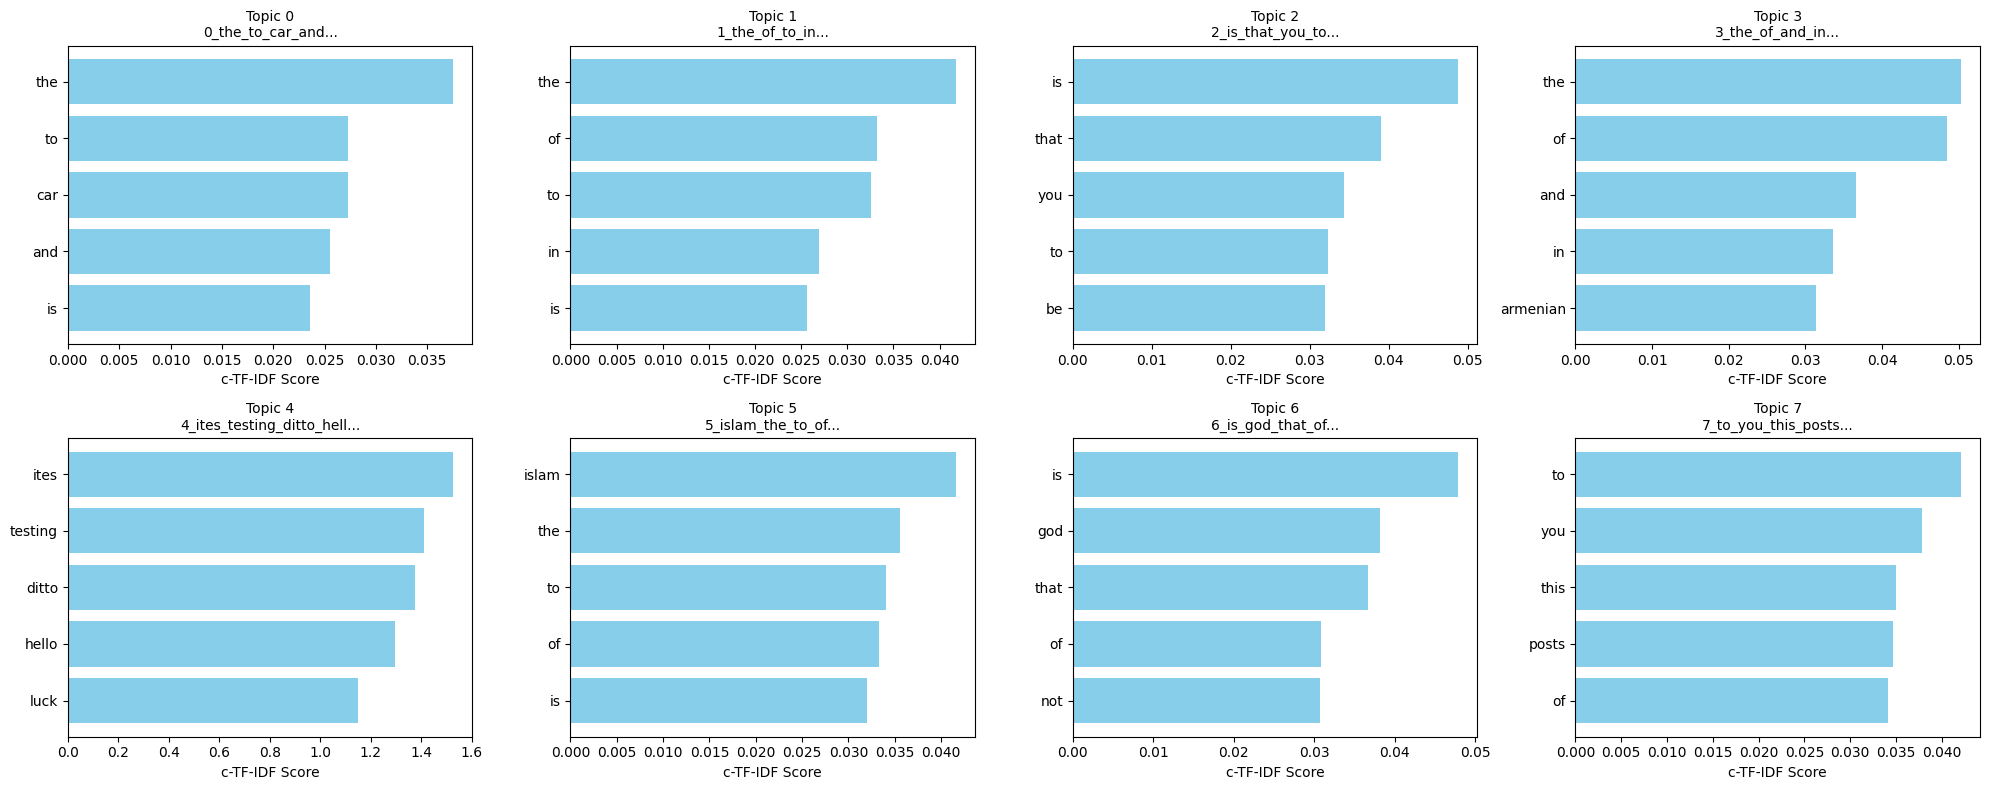


2. Generating Static Topic Distance Map...


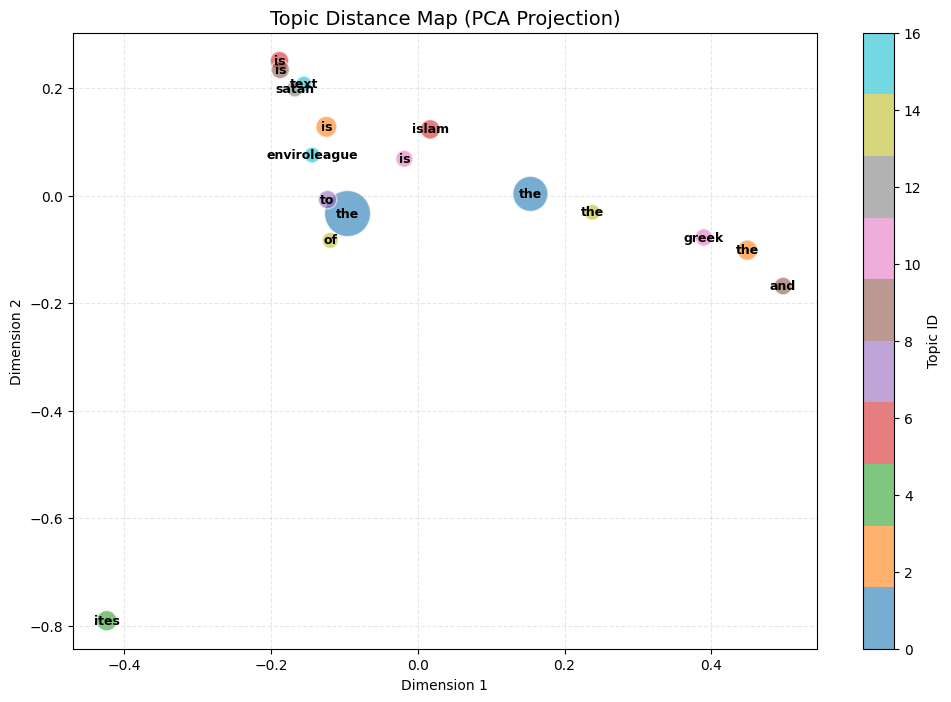

In [ ]:
import numpy as np
import re
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

### **Step 4: Visualization**
print("\n--- Step 4: Visualization ---")

# Refresh topic info to reflect custom labels
topic_info = topic_model.get_topic_info()
relevant_topics = topic_info[topic_info['Topic'] != -1].copy()

# Ensure topic_mapping exists; if not, fall back to default Name
if 'topic_mapping' not in locals():
    topic_mapping = {} 
relevant_topics['Display_Name'] = relevant_topics['Topic'].map(topic_mapping).fillna(relevant_topics['Name'])

# --- Part 1: Bar Chart of Top Words per Topic ---
print("1. Generating Bar Chart of Top Words...")

relevant_topics_plot = relevant_topics

# Prepare the plot grid
n_topics = len(relevant_topics_plot)
n_cols = 4
n_rows = (n_topics + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4 * n_rows), sharex=False)
axes = axes.flatten()

for i, (index, row) in enumerate(relevant_topics_plot.iterrows()):
    topic_id = row["Topic"]
    topic_name = row["Display_Name"]
    top_words_data = topic_model.get_topic(topic_id)[:5]
    words = [w for w, _ in top_words_data]
    scores = [s for _, s in top_words_data]

    top_word = words[0] if words else ""
    ax = axes[i]
    y_pos = np.arange(len(words))
    ax.barh(y_pos, scores, align="center", color="skyblue")
    ax.set_yticks(y_pos)
    ax.set_yticklabels(words)
    ax.invert_yaxis()
    ax.set_title(f"Topic {topic_id}: {topic_name}", fontsize=10)
    ax.set_xlabel("c-TF-IDF Score")

# Hide any empty subplots
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

# --- Part 2: Static Topic Distance Map ---
print("\n2. Generating Static Topic Distance Map...")

if topic_model.topic_embeddings_ is not None:
    embeddings = np.array(topic_model.topic_embeddings_)

    df_map = topic_model.get_topic_info()
    df_map['Display_Name'] = df_map['Topic'].map(topic_mapping).fillna(df_map['Name'])

    mask = df_map['Topic'] != -1
    clean_ids = df_map.loc[mask, 'Topic'].values
    clean_names = df_map.loc[mask, 'Display_Name'].values
    clean_counts = df_map.loc[mask, 'Count'].values

    # Retrieve embeddings corresponding to non-outlier topics
    clean_embeddings = embeddings[df_map.index[mask]]

    # Perform PCA via SVD
    mean_vec = np.mean(clean_embeddings, axis=0)
    centered_data = clean_embeddings - mean_vec
    U, S, Vt = np.linalg.svd(centered_data, full_matrices=False)

    coords = U[:, :2] * S[:2]
    x = coords[:, 0]
    y = coords[:, 1]

    plt.figure(figsize=(14, 10))

    # Scale bubble sizes based on topic count
    sizes = clean_counts / clean_counts.max() * 1000 + 100

    # --- COLOR MAPPING FOR EDGES ---
    # Create a colormap (using tab20 for good distinction)
    cmap = plt.get_cmap('tab20')
    norm = mcolors.Normalize(vmin=np.min(clean_ids), vmax=np.max(clean_ids))
    
    # Generate colors for the edges based on Topic ID
    edge_colors = cmap(norm(clean_ids))

    # --- PLOT WITH "EDGE FRAMES" ---
    # c='white': Sets the inside of the bubble to white
    # edgecolors=edge_colors: Sets the rim color
    # linewidths=3: Makes the rim thick and visible
    scatter = plt.scatter(x, y, s=sizes, c='white', edgecolors=edge_colors, linewidths=3, alpha=0.9)

    # --- ANNOTATION LOOP ---
    for i, txt in enumerate(clean_names):
        topic_id = clean_ids[i]
        
        # 1. Fetch the actual top word
        top_words_list = topic_model.get_topic(topic_id)
        top_word = top_words_list[0][0] if top_words_list else ""

        # 2. Determine display title
        if re.match(r'^-?\d+_', txt):
            display_title = f"Topic {topic_id}"
        else:
            display_title = txt

        # 3. Construct label
        label_text = f"{display_title}\n(top: {top_word})"

        # Note: We match the box edge color to the bubble edge color for consistency
        this_color = cmap(norm(topic_id))
        
        plt.annotate(label_text, (x[i], y[i]), 
                     ha='center', va='center', 
                     fontsize=9, fontweight='bold',
                     bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=this_color, lw=2, alpha=0.9))

    plt.title("Topic Distance Map (PCA Projection)", fontsize=16)
    plt.xlabel("Dimension 1")
    plt.ylabel("Dimension 2")
    plt.grid(True, linestyle='--', alpha=0.3)
    
    # Create a Colorbar (mapped to the edge colors)
    # FIX: Added ax=plt.gca() to explicitly tell matplotlib where to put the colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    plt.colorbar(sm, ax=plt.gca(), label="Topic ID")
    
    plt.show()

else:
    print("Error: Topic embeddings not found in model. Cannot generate Distance Map.")

### **Step 5: New Document Test**

In [ ]:
# TO DO

### **Step 5: New Document Test**

# 1. Write 3 new articles (one per category)
# These are custom strings representing "Atheism", "Autos", and "MiddleEast"
new_articles = [
    # Article 1: Intended for 'Atheism'
    """
    The debate regarding the existence of a higher power often centers on 
    philosophical arguments rather than empirical evidence. Many secular 
    humanists argue that morality exists independently of religious doctrine 
    and that ethical behavior is an evolutionary trait rather than a divine mandate.
    """,

    # Article 2: Intended for 'Autos'
    """
    The new V8 engine offers superior torque and acceleration compared to the 
    previous V6 model. During the test drive, the transmission shifted smoothly, 
    and the suspension handled the corners with ease. Fuel economy remains a concern 
    for vehicles in this class, but the performance is undeniable.
    """,

    # Article 3: Intended for 'MiddleEast' (Politics)
    """
    Diplomatic relations between Israel and neighboring countries have been 
    a subject of intense negotiation this year. The peace treaty discussions 
    are stalled, and recent conflicts in the Gaza strip have led to international 
    calls for a ceasefire. The Armenian and Turkish delegation also met to discuss borders.
    """
]

# 2. Predict topics using the trained model
predicted_topics, predicted_probs = topic_model.transform(new_articles)

# Display Results
print("\n--- Prediction Results for New Documents ---")
df_info = topic_model.get_topic_info()

for i, doc in enumerate(new_articles):
    topic_id = predicted_topics[i]
    
    # Retrieve the custom label (Name) we assigned in Step 3
    # If the model has custom labels set, 'Name' or 'CustomName' column holds it.
    if topic_id == -1:
        topic_name = "Outlier"
    else:
        # Get the name from the internal topic info
        topic_name = df_info.loc[df_info['Topic'] == topic_id, 'Name'].values[0]
        # If you used set_topic_labels in Step 3, you can also access .custom_labels_
        if topic_model.custom_labels_ is not None:
             topic_name = topic_model.custom_labels_[topic_id + topic_model._outliers]

    print(f"\nDocument {i+1} Preview: {doc.strip()[:80]}...")
    print(f"Predicted Topic ID: {topic_id}")
    print(f"Predicted Label:    {topic_name}")


--- Prediction Results for New Documents ---

Document 1 Preview: The debate regarding the existence of a higher power often centers on 
    philo...
Predicted Topic ID: 2
Predicted Label:    Atheism

Document 2 Preview: The new V8 engine offers superior torque and acceleration compared to the 
    p...
Predicted Topic ID: 0
Predicted Label:    Autos

Document 3 Preview: Diplomatic relations between Israel and neighboring countries have been 
    a s...
Predicted Topic ID: 1
Predicted Label:    MiddleEast
